In [ ]:
# -------- -------- ----
# Libraries for data manipulation
# -------- -------- ----
import pandas as pd       # To manipulate data tables (DataFrame)
import numpy as np        # For scientific computation and numerical array manipulation
import json               # To read and write JSON files
import re                 # To work with regular expressions (search and replace text)
import sys                # To interact with the system (arguments, paths, Python version)
import itertools          # To generate combinations, permutations or advanced iterations

# -------- -------- ----
# Libraries for machine learning and text processing
# -------- -------- ----
from sklearn.feature_extraction.text import TfidfVectorizer  # Transforms text into numerical vectors (TF-IDF)
from sklearn.metrics.pairwise import cosine_similarity       # Calculates similarity between vectors (often for text comparison)
from sklearn.preprocessing import MinMaxScaler               # Normalizes numerical values between 0 and 1

# -------- -------- ----
# Visualization library
# -------- -------- ----
import matplotlib.pyplot as plt  # To create charts

# -------- -------- ----
# Libraries for accessing Spotify API
# -------- -------- ----
import spotipy                              # Main library for interacting with Spotify API
from spotipy.oauth2 import SpotifyClientCredentials  # Authentication without user account (read-only)
from spotipy.oauth2 import SpotifyOAuth             # Authentication with a Spotify account (read/write on behalf of user)
import spotipy.util as util                          # Practical utilities, particularly for authentication

# -------- -------- ----
# Warning management
# -------- -------- ----
import warnings
warnings.filterwarnings("ignore")  # Ignore warning messages for cleaner display

# -------- -------- ----
# Configuration for Jupyter Notebook
# -------- -------- ----
%matplotlib inline  
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))  # Enlarges notebook width for better readability

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option("display.max_rows", None)

In [3]:
!kaggle datasets download -d yamaerenay/spotify-dataset-19212020-600k-tracks
!kaggle datasets download -d yamaerenay/spotify-dataset-1921-2020-160k-tracks
import zipfile

with zipfile.ZipFile("spotify-dataset-19212020-600k-tracks.zip", 'r') as zip_ref:
    zip_ref.extractall("data")
with zipfile.ZipFile("spotify-dataset-1921-2020-160k-tracks.zip", 'r') as zip_ref:
    zip_ref.extractall("data_160k")



Dataset URL: https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks
License(s): Community Data License Agreement - Sharing - Version 1.0
spotify-dataset-19212020-600k-tracks.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-1921-2020-160k-tracks
License(s): Community Data License Agreement - Sharing - Version 1.0
spotify-dataset-1921-2020-160k-tracks.zip: Skipping, found more recently modified local copy (use --force to force download)


In [4]:
spotify_df = pd.read_csv('data_160k/data.csv')
spotify_df.head()


,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
0,0.0594,1921,0.982,"['Sergei Rachmaninoff', 'James Levine', 'Berli...",0.279,831667,0.211,0,4BJqT0PrAfrxzMOxytFOIz,0.878000,10,0.665,-20.096,1,"Piano Concerto No. 3 in D Minor, Op. 30: III. ...",4,1921,0.0366,80.954
1,0.9630,1921,0.732,['Dennis Day'],0.819,180533,0.341,0,7xPhfUan2yNtyFG0cUWkt8,0.000000,7,0.160,-12.441,1,Clancy Lowered the Boom,5,1921,0.4150,60.936
2,0.0394,1921,0.961,['KHP Kridhamardawa Karaton Ngayogyakarta Hadi...,0.328,500062,0.166,0,1o6I8BglA6ylDMrIELygv1,0.913000,3,0.101,-14.850,1,Gati Bali,5,1921,0.0339,110.339
3,0.1650,1921,0.967,['Frank Parker'],0.275,210000,0.309,0,3ftBPsC5vPBKxYSee08FDH,0.000028,5,0.381,-9.316,1,Danny Boy,3,1921,0.0354,100.109
4,0.2530,1921,0.957,['Phil Regan'],0.418,166693,0.193,0,4d6HGyGT8e121BsdKmw9v6,0.000002,3,0.229,-10.096,1,When Irish Eyes Are Smiling,2,1921,0.0380,101.665


In [5]:
data_w_genre = pd.read_csv('data_160k/data_w_genres.csv')
data_w_genre.head()


,genres,artists,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,key,mode,count
0,['show tunes'],"""Cats"" 1981 Original London Cast",0.590111,0.467222,250318.555556,0.394003,0.011400,0.290833,-14.448000,0.210389,117.518111,0.389500,38.333333,5,1,9
1,[],"""Cats"" 1983 Broadway Cast",0.862538,0.441731,287280.000000,0.406808,0.081158,0.315215,-10.690000,0.176212,103.044154,0.268865,30.576923,5,1,26
2,[],"""Fiddler On The Roof” Motion Picture Chorus",0.856571,0.348286,328920.000000,0.286571,0.024593,0.325786,-15.230714,0.118514,77.375857,0.354857,34.857143,0,1,7
3,[],"""Fiddler On The Roof” Motion Picture Orchestra",0.884926,0.425074,262890.962963,0.245770,0.073587,0.275481,-15.639370,0.123200,88.667630,0.372030,34.851852,0,1,27
4,[],"""Joseph And The Amazing Technicolor Dreamcoat""...",0.510714,0.467143,270436.142857,0.488286,0.009400,0.195000,-10.236714,0.098543,122.835857,0.482286,43.000000,5,1,7


In [ ]:
data_w_genre.dtypes
print(data_w_genre['genres'].head())

print(type(data_w_genre['genres'].iloc[0]))  # iloc for first row of csv

0    ['show tunes']
1                []
2                []
3                []
4                []
Name: genres, dtype: object
<class 'str'>


In [ ]:
# Extract genres into list and replace spaces with underscores
data_w_genre['genres_upd'] = data_w_genre['genres'].apply(lambda x: [re.sub(' ','_',i) for i in re.findall(r"'([^']*)'", x)])
# re.findall(r"'([^']*)'", x) to extract items between single quotes and put them in a list, and re.sub(' ','_',i) to replace spaces with underscores in each extracted genre.
print(data_w_genre['genres_upd'].head())
print(type(data_w_genre['genres_upd'].iloc[0]))  # ([^']*) means: "Capture everything that is not a quote".

0    [show_tunes]
1              []
2              []
3              []
4              []
Name: genres_upd, dtype: object
<class 'list'>


In [ ]:
spotify_df['artists_upd_v1'] = spotify_df['artists'].apply(lambda x: re.findall(r"'([^']*)'", x))  # re.findall returns a list of artists
print(spotify_df['artists_upd_v1'].head())
print(type(spotify_df['artists_upd_v1'].iloc[0]))

0    [Sergei Rachmaninoff, James Levine, Berliner P...
1                                         [Dennis Day]
2    [KHP Kridhamardawa Karaton Ngayogyakarta Hadin...
3                                       [Frank Parker]
4                                         [Phil Regan]
Name: artists_upd_v1, dtype: object
<class 'list'>


In [ ]:
spotify_df[spotify_df['artists_upd_v1'].apply(lambda x: not x)].head(5)  # Missing artists because some dataset rows are not in format '...', so v1 cannot extract anything.

,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,artists_upd_v1
143,0.300,1921,0.772,"[""Scarlet D'Carpio""]",0.560,249370,0.313,0,7b4eHImKQ51DYaQvNTdtEp,0.000005,6,0.115,-8.346,0,Himno Nacional del Perú,0,1921-09-23,0.0376,107.501,[]
234,0.902,1923,0.994,"[""King Oliver's Creole Jazz Band""]",0.708,194533,0.361,0,1xEEYhWxT4WhDQdxfPCT8D,0.883000,0,0.103,-11.764,0,Snake Rag,20,1923,0.0441,105.695,[]
238,0.554,1923,0.996,"[""King Oliver's Creole Jazz Band""]",0.546,170827,0.189,0,3rauXVLOOM5BlxWqUcDpkg,0.908000,0,0.339,-15.984,1,Chimes Blues,13,1923,0.0581,80.318,[]
244,0.319,1923,0.995,"[""Clarence Williams' Blue Five""]",0.520,197493,0.153,0,1UdqHVRFYMZKU2Q7xkLtYc,0.131000,0,0.353,-14.042,1,Pickin' On Your Baby,11,1923,0.0440,102.937,[]
249,0.753,1923,0.994,"[""King Oliver's Creole Jazz Band""]",0.359,187227,0.357,0,5SvyP1ZeJX1jA7AOZD08NA,0.819000,3,0.290,-11.810,1,Tears,10,1923,0.0511,205.053,[]


In [ ]:
spotify_df['artists_upd_v2'] = spotify_df['artists'].apply(lambda x: re.findall(r'"(.*?)"',x))  # Search for everything between double quotes
spotify_df['artists_upd'] = np.where(spotify_df['artists_upd_v1'].apply(lambda x: not x), spotify_df['artists_upd_v2'], spotify_df['artists_upd_v1'])  # If x is [] (empty), not x becomes True. We take the value of artists_upd_v2, otherwise we take artists_upd_v1.

In [ ]:
# Create 'artists_song' column by concatenating the first artist and song name (unique ID, as some songs with same name have different ids)
spotify_df['artists_song'] = spotify_df.apply(lambda row: row['artists_upd'][0]+row['name'],axis = 1)  # axis=1 → works row by row (axis 0 → column by column)

In [ ]:
spotify_df.sort_values(['artists_song','release_date'], ascending = False, inplace = True)  # inplace=True modifies the existing dataframe
duplicates = spotify_df[spotify_df['name'].duplicated(keep=False)]  # Display all duplicates when keep=false
print(duplicates['name'].sample(20))
spotify_df[spotify_df['name']=='La Vie en rose']

54975                                    That's Not My Name
42725      A Midsummer Night's Dream, Op. 61: Wedding March
4641               Jingle Bells (with The Ken Lane Singers)
130491                                        Porpoise Song
12672                            Things Can Only Get Better
32511                         The Church On Cumberland Road
168280                                           You Got Me
26141                                             Honey Bee
132839                                         Take Me Down
34161                                              Nebraska
101532                                    Answering Machine
108563                                             Untitled
47421                                           Be My Lover
13157                                            Lovin' You
104892                          I See The Want In Your Eyes
55393     The Chipmunk Song (Christmas Don't Be Late) - ...
61889            Sonata No. 1, BWV 1001,

,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,artists_upd_v1,artists_upd_v2,artists_upd,artists_song
36176,0.338,2008,0.981,['Édith Piaf'],0.371,187733,0.278,0,3lAun9V0YdTlCSIEXPvfsY,0.0,7,0.272,-8.596,0,La Vie en rose,64,2008-10-13,0.0303,82.331,[Édith Piaf],[],[Édith Piaf],Édith PiafLa Vie en rose
13155,0.338,1987,0.981,['Édith Piaf'],0.371,187733,0.278,0,6RKuyWarJu8SMrflntmyXx,0.0,7,0.272,-8.596,0,La Vie en rose,51,1987-10-31,0.0303,82.331,[Édith Piaf],[],[Édith Piaf],Édith PiafLa Vie en rose
50673,0.338,1987,0.981,['Édith Piaf'],0.371,187733,0.278,0,6By5EZtl0GKQuRZBZbk1LU,0.0,7,0.272,-8.596,0,La Vie en rose,38,1987-10-31,0.0303,82.331,[Édith Piaf],[],[Édith Piaf],Édith PiafLa Vie en rose


In [13]:
spotify_df.drop_duplicates('artists_song',inplace = True)
spotify_df[spotify_df['name']=='La Vie en rose']


,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,artists_upd_v1,artists_upd_v2,artists_upd,artists_song
36176,0.338,2008,0.981,['Édith Piaf'],0.371,187733,0.278,0,3lAun9V0YdTlCSIEXPvfsY,0.0,7,0.272,-8.596,0,La Vie en rose,64,2008-10-13,0.0303,82.331,[Édith Piaf],[],[Édith Piaf],Édith PiafLa Vie en rose


In [ ]:
artists_exploded = spotify_df[['artists_upd','id']].explode('artists_upd')  # explode creates one row for each element in the 'artists_upd' list, duplicating other columns (here 'id') for each element.

In [ ]:
artists_exploded_enriched = artists_exploded.merge(data_w_genre, how = 'left', left_on = 'artists_upd',right_on = 'artists')  # Left join to add genres to artists
artists_exploded_enriched_nonnull = artists_exploded_enriched[~artists_exploded_enriched.genres_upd.isnull()]  # Keep only rows where genres_upd is not null
duplicates = artists_exploded_enriched[artists_exploded_enriched['id'].duplicated(keep=False)]  # If an artist is not present at all in the genres reference, Pandas puts NaN in the genres_upd column. So we remove these rows with ~isnull()
print(duplicates['id'].sample(20)) 
artists_exploded_enriched_nonnull[artists_exploded_enriched_nonnull['id'] =='6ldUubUfnH9Msuw7bukP6P']

165943    095EkSUvqvkb6LhCSWnmfK
61765     1fnRwgZLgAYMM1dVL1oqwG
124009    6hkr5ZGVOt3Z2BNGE6yqpB
165057    0AyyghSd69eM268EbhL8hL
206056    2kE82JhBcoS7mimFO1SqqX
8480      5htpUDvTIPfrp9eVzIkj56
111588    2BX3l3Hw2BPNtQofmugHXN
34785     0n9toZOivQbcwGuwNsPywM
198280    3M4OxUpLqSexH8IioAxXZz
7848      1VxE8GajW9FCYcYIK44tVe
117550    0mVkPe7vgOAzBH9QZw7KVN
135236    2AqREaPXIX3pHMxMkxhgvF
80626     6OxTGWA4bxZ1u1auaeTDNv
54996     5UXzUPljQdGQ6sAVZAttm3
122689    1MjMBrPgiBOLB8U3Si311r
8049      6u3UVuVTsLY3K1phDc3RH6
198037    1CzeuSrm71wHP9qsjg7p3F
191792    5P6ySmn4cxd3pF4BNeMOIG
57821     1CDEWKmyRTPWWa7uIKVSU4
51827     0rjVBLq39kG9yMn6KWXyrm
Name: id, dtype: object


,artists_upd,id,genres,artists,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,key,mode,count,genres_upd
70322,Ninon Vallin,6ldUubUfnH9Msuw7bukP6P,['vintage classical singing'],Ninon Vallin,0.928816,0.301663,190149.894737,0.171337,0.100270,0.317053,-16.804974,0.050979,87.908947,0.187737,0.0,2.0,1.0,38.0,[vintage_classical_singing]
70323,Georges Thill,6ldUubUfnH9Msuw7bukP6P,[],Georges Thill,0.936471,0.307446,210622.314286,0.152086,0.092751,0.261371,-16.321271,0.066120,89.643971,0.170014,0.0,5.0,1.0,70.0,[]
70324,Germaine Féraldy,6ldUubUfnH9Msuw7bukP6P,[],Germaine Féraldy,0.928816,0.301663,190149.894737,0.171337,0.100270,0.317053,-16.804974,0.050979,87.908947,0.187737,0.0,2.0,1.0,38.0,[]


In [ ]:
artists_genres_consolidated = artists_exploded_enriched_nonnull.groupby('id')['genres_upd'].apply(list).reset_index()  # Groups genres by song id into a list of lists

In [17]:
artists_genres_consolidated['consolidates_genre_lists'] = artists_genres_consolidated['genres_upd'].apply(lambda x: list(set(list(itertools.chain.from_iterable(x)))))
artists_genres_consolidated.head()

,id,genres_upd,consolidates_genre_lists
0,000G1xMMuwxNHmwVsBdtj1,"[[candy_pop, dance_rock, new_wave, new_wave_po...","[new_wave_pop, rock, power_pop, candy_pop, new..."
1,000GyYHG4uWmlXieKLij8u,"[[alternative_hip_hop, conscious_hip_hop, minn...","[alternative_hip_hop, minnesota_hip_hop, consc..."
2,000Npgk5e2SgwGaIsN3ztv,"[[classic_bollywood, classic_pakistani_pop, fi...","[classic_bollywood, sufi, ghazal, filmi, class..."
3,000ZxLGm7jDlWCHtcXSeBe,"[[boogie-woogie, piano_blues, ragtime, stride]]","[boogie-woogie, stride, piano_blues, ragtime]"
4,000jBcNljWTnyjB4YO7ojf,[[]],[]


In [18]:
spotify_df = spotify_df.merge(artists_genres_consolidated[['id','consolidates_genre_lists']], on = 'id',how = 'left')
spotify_df.tail()

,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,artists_upd_v1,artists_upd_v2,artists_upd,artists_song,consolidates_genre_lists
156602,0.768,1997,0.2820,"[""Lil' Kim"", ""Lil' Cease""]",0.748,275947,0.693,0,2LP2uDQQ7eLMcUVE4aOpAV,0.00000,11,0.123,-7.832,0,Crush on You (feat. Lil' Cease) - Remix,56,1997-06-30,0.2780,88.802,"[ Kim"", ""Lil]","[Lil' Kim, Lil' Cease]","[ Kim"", ""Lil]","Kim"", ""LilCrush on You (feat. Lil' Cease) - R...",NaN
156603,0.792,2004,0.0248,"[""Lil' Flip"", 'Lea']",0.814,225173,0.387,1,4s0o8TJHfX9LLHa0umnOzT,0.00000,0,0.131,-9.867,1,Sunshine (feat. Lea),62,2004-03-30,0.0945,93.961,"[ Flip"", ]",[Lil' Flip],"[ Flip"", ]","Flip"", Sunshine (feat. Lea)",NaN
156604,0.697,1999,0.0516,"[""Ol' Dirty Bastard"", 'Kelis', 'Rich Travali']",0.934,239547,0.459,1,6YYd5MLpu45J0uLrMdivF7,0.00000,1,0.222,-7.654,1,Got Your Money (feat. Kelis),66,1999,0.1890,103.040,"[ Dirty Bastard"", , , ]",[Ol' Dirty Bastard],"[ Dirty Bastard"", , , ]","Dirty Bastard"", Got Your Money (feat. Kelis)",NaN
156605,0.429,1994,0.0249,"[""World Class Wreckin' Cru"", ""Michel 'Le""]",0.715,351040,0.490,0,3hoiinUc5VA9xUEJID7R8V,0.00017,9,0.139,-9.504,0,Turn Off The Lights - Rap,36,1994-04-06,0.0479,129.309,"[ Cru"", ""Michel ]","[World Class Wreckin' Cru, Michel 'Le]","[ Cru"", ""Michel ]","Cru"", ""Michel Turn Off The Lights - Rap",NaN
156606,0.273,1996,0.0113,"[""Rappin' 4-Tay"", 'MC Breed', 'Too $hort']",0.897,337973,0.414,1,78859Af0fmA9VTlgnOHTAP,0.00011,4,0.101,-8.450,0,Never Talk Down,35,1996,0.2460,96.039,"[ 4-Tay"", , , ]",[Rappin' 4-Tay],"[ 4-Tay"", , , ]","4-Tay"", Never Talk Down",NaN


In [19]:
spotify_df['year'] = spotify_df['release_date'].apply(lambda x: x.split('-')[0])

In [ ]:
float_cols = spotify_df.dtypes[spotify_df.dtypes == 'float64'].index.values  # Print float64 type columns (to normalize)
print(float_cols)

['valence' 'acousticness' 'danceability' 'energy' 'instrumentalness'
 'liveness' 'loudness' 'speechiness' 'tempo']


In [21]:
ohe_cols = 'popularity'

In [22]:
spotify_df['popularity'].describe()

count    156607.000000
mean         31.307215
std          21.712234
min           0.000000
25%          11.000000
50%          33.000000
75%          48.000000
max         100.000000
Name: popularity, dtype: float64

In [23]:
# create 5 point buckets for popularity 
spotify_df['popularity_red'] = spotify_df['popularity'].apply(lambda x: int(x/5))

In [24]:
spotify_df['consolidates_genre_lists'] = spotify_df['consolidates_genre_lists'].apply(lambda d: d if isinstance(d, list) else [])
spotify_df.head()

,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,artists_upd_v1,artists_upd_v2,artists_upd,artists_song,consolidates_genre_lists,popularity_red
0,0.177,1989,0.568,['조정현'],0.447,237688,0.2150,0,2ghebdwe2pNXT4eL34T7pW,0.000001,10,0.0649,-16.478,1,그아픔까지사랑한거야,31,1989-06-15,0.0272,71.979,[조정현],[],[조정현],조정현그아픔까지사랑한거야,[classic_korean_pop],6
1,0.352,1992,0.381,['黑豹'],0.353,316160,0.6860,0,3KIuCzckjdeeVuswPo20mC,0.000000,11,0.0568,-9.103,1,DON'T BREAK MY HEART,35,1992-12-22,0.0395,200.341,[黑豹],[],[黑豹],黑豹DON'T BREAK MY HEART,"[chinese_indie, chinese_indie_rock]",7
2,0.458,1963,0.987,['黃國隆'],0.241,193480,0.0437,0,4prhqrLXYMjHJ6vpRAlasx,0.000453,5,0.2650,-24.571,1,藝旦調,23,1963-05-28,0.0443,85.936,[黃國隆],[],[黃國隆],黃國隆藝旦調,[],4
3,0.796,1963,0.852,"['黃國隆', '王秋玉']",0.711,145720,0.1110,0,5xFXTvnEe03SyvFpo6pEaE,0.000000,2,0.0695,-20.741,0,草螟弄雞公,23,1963-05-28,0.0697,124.273,"[黃國隆, 王秋玉]",[],"[黃國隆, 王秋玉]",黃國隆草螟弄雞公,[],4
4,0.704,1963,0.771,['黃國隆'],0.610,208760,0.1750,0,6Pqs2suXEqCGx7Lxg5dlrB,0.000000,7,0.0309,-20.232,1,思想起,23,1963-05-28,0.0419,124.662,[黃國隆],[],[黃國隆],黃國隆思想起,[],4


In [ ]:
def ohe_prep(df, column, new_name): 
    """ 
    Create One Hot Encoded features of a specific column

    Parameters: 
        df (pandas dataframe): Spotify Dataframe
        column (str): Column to be processed
        new_name (str): new column name to be used
        
    Returns: 
        tf_df: One hot encoded features 
    """
    
    tf_df = pd.get_dummies(df[column])  # get_dummies creates a new column for each unique value found in your original column
    feature_names = tf_df.columns
    tf_df.columns = [new_name + "|" + str(i) for i in feature_names]
    tf_df.reset_index(drop = True, inplace = True)  # INDEX REALIGNMENT: Crucial for future merging
# 1. 'drop=True': Prevents Pandas from converting old index into a new useless column.
# 2. 'inplace=True': Modifies the array directly in memory to save space.
# WHY? If you deleted duplicates before, your indexes are no longer continuous (ex: 0, 2, 5...).
# This line ensures that this array of 0s and 1s starts at 0 and follows the exact order of spotify_df,
# avoiding the creation of empty rows (NaN) when merging final features.  
    return tf_df

In [ ]:
# Function to build entire feature set
def create_feature_set(df, float_cols):
    """ 
    Process spotify df to create a final set of features that will be used to generate recommendations

    Parameters: 
        df (pandas dataframe): Spotify Dataframe
        float_cols (list(str)): List of float columns that will be scaled 
        
    Returns: 
        final: final set of features 
    """
    
    # TF-IDF genre lists
    tfidf = TfidfVectorizer()  # A big machine to scan genres, it starts empty, its purpose is to create TF-IDF vectors
    tfidf_matrix = tfidf.fit_transform(df['consolidates_genre_lists'].apply(lambda x: " ".join(x)))  # TF-IDF doesn't understand Python lists like ['pop', 'rock']. This little function takes each list and "glues" the words with a space to make a sentence: "pop rock". Fit: The machine reads all genres from all your songs and creates a giant dictionary (ex: 0 = 'blues', 1 = 'jazz', 2 = 'pop'...).
    # Transform: It replaces the words with mathematical scores.
    genre_df = pd.DataFrame(tfidf_matrix.toarray())  # The tfidf matrix as DataFrame. The problem at this stage: Your columns don't have names like "pop" or "rock" yet, they're called 0, 1, 2, 3.... That's unreadable.
    genre_df.columns = ['genre' + "|" + i for i in tfidf.get_feature_names_out()]  # Column names (basically I just have numbers and that's why I'm getting the column names)
    genre_df.reset_index(drop = True, inplace=True)  # So indexes match those of df (0,1,2,3)
    
    # explicity_ohe = ohe_prep(df, 'explicit','exp')    
    year_ohe = ohe_prep(df, 'year','year') * 0.5  # Creates one-hot encoded columns for each year, then weighted by 0.5
    popularity_ohe = ohe_prep(df, 'popularity_red','pop') * 0.15
    
    # Scale float columns
    floats = df[float_cols].reset_index(drop = True)
    scaler = MinMaxScaler()  # To normalize values between 0 and 1
    floats_scaled = pd.DataFrame(scaler.fit_transform(floats), columns = floats.columns) * 0.2
    
    # Concatenate all features
    final = pd.concat([genre_df, floats_scaled, popularity_ohe, year_ohe], axis = 1)
     
    # Add song id
    final['id']=df['id'].values
    
    return final  # I have my normalized float columns, my TF-IDF of my genre columns, and my one-hot encoding of year and popularity

In [27]:
complete_feature_set = create_feature_set(spotify_df, float_cols=float_cols)#.mean(axis = 0)

In [28]:
complete_feature_set.head()

genre|21st_century_classical  genre|432hz  genre|_hip_hop  \
0                           0.0          0.0             0.0   
1                           0.0          0.0             0.0   
2                           0.0          0.0             0.0   
3                           0.0          0.0             0.0   
4                           0.0          0.0             0.0   

   genre|a_cappella  genre|abstract  genre|abstract_beats  \
0               0.0             0.0                   0.0   
1               0.0             0.0                   0.0   
2               0.0             0.0                   0.0   
3               0.0             0.0                   0.0   
4               0.0             0.0                   0.0   

   genre|abstract_hip_hop  genre|accordeon  genre|accordion  genre|acid_house  \
0                     0.0              0.0              0.0               0.0   
1                     0.0              0.0              0.0               0.0   
2                     0.0              0.0              0.0               0.0   
3                     0.0              0.0              0.0               0.0   
4                     0.0              0.0              0.0               0.0   

   genre|acid_rock  genre|acid_trance  genre|acousmatic  genre|acoustic  \
0              0.0                0.0               0.0             0.0   
1              0.0                0.0               0.0             0.0   
2              0.0                0.0               0.0             0.0   
3              0.0                0.0               0.0             0.0   
4              0.0                0.0               0.0             0.0   

   genre|acoustic_blues  genre|acoustic_pop  genre|acoustic_punk  \
0                   0.0                 0.0                  0.0   
1                   0.0                 0.0                  0.0   
2                   0.0                 0.0                  0.0   
3                   0.0                 0.0                  0.0   
4                   0.0                 0.0                  0.0   

   genre|acoustic_rock  genre|action_rock  genre|adoracion  \
0                  0.0                0.0              0.0   
1                  0.0                0.0              0.0   
2                  0.0                0.0              0.0   
3                  0.0                0.0              0.0   
4                  0.0                0.0              0.0   

   genre|adult_standards  genre|adventista  genre|afghan_pop  \
0                    0.0               0.0               0.0   
1                    0.0               0.0               0.0   
2                    0.0               0.0               0.0   
3                    0.0               0.0               0.0   
4                    0.0               0.0               0.0   

   genre|afghan_traditional  genre|african  genre|african_percussion  \
0                       0.0            0.0                       0.0   
1                       0.0            0.0                       0.0   
2                       0.0            0.0                       0.0   
3                       0.0            0.0                       0.0   
4                       0.0            0.0                       0.0   

   genre|african_reggae  genre|african_rock  genre|afro  genre|afro_dancehall  \
0                   0.0                 0.0         0.0                   0.0   
1                   0.0                 0.0         0.0                   0.0   
2                   0.0                 0.0         0.0                   0.0   
3                   0.0                 0.0         0.0                   0.0   
4                   0.0                 0.0         0.0                   0.0   

   genre|afro_house  genre|afro_psych  genre|afro_soul  genre|afrobeat  \
0               0.0               0.0              0.0             0.0   
1               0.0               0.0              0.0             0.0   
2   

In [29]:
import os

# Spotify API credentials are read from the environment (never commit them).
client_id = os.environ["SPOTIPY_CLIENT_ID"]
client_secret = os.environ["SPOTIPY_CLIENT_SECRET"]

In [ ]:
scope = 'user-library-read'  # Read-only permission on user library

if len(sys.argv) > 1:  # sys.argv is a list of arguments passed to the Python script from the command line
    username = sys.argv[1]
else:
    print("Usage: %s username" % (sys.argv[0],))
    sys.exit()

In [31]:
auth_manager = SpotifyClientCredentials(client_id=client_id, client_secret=client_secret)
sp = spotipy.Spotify(auth_manager=auth_manager)

In [32]:
token = util.prompt_for_user_token(scope, client_id= client_id, client_secret=client_secret, redirect_uri='https://127.0.0.1:8888/callback')

In [33]:
sp = spotipy.Spotify(auth=token)

In [ ]:
id_name = {}
list_photo = {}

for i in sp.current_user_playlists()['items']:
    playlist_id = i['uri'].split(':')[2]
    id_name[i['name']] = playlist_id
    
    # Check if 'images' exists and is not empty
    if i['images'] and len(i['images']) > 0:
        list_photo[playlist_id] = i['images'][0]['url']
    else:
        # Put a default image or text if no image
        list_photo[playlist_id] = "No image available"

In [35]:
id_name

{'Ma liste de lecture #5': '4LbyG1dVKEzVg90D5vn06g',
 'Ma liste de lecture #4': '3RBM8jaNnHmpurUkABHylW',
 'Ma liste de lecture #3': '2G5Dm2495GWSApmzWCniJX',
 'Ma liste de lecture #2': '2R2SGPDDWOkdaH72RjrXtc',
 'Ma liste de lecture #1': '4LO8yhyjp8pMZhsqDSKr37'}

In [ ]:
def create_necessary_outputs(playlist_name,id_dic, df):
    """ 
    Pull songs from a specific playlist.

    Parameters: 
        playlist_name (str): name of the playlist you'd like to pull from the spotify API
        id_dic (dic): dictionary that maps playlist_name to playlist_id
        df (pandas dataframe): spotify dataframe
        
    Returns: 
        playlist: all songs in the playlist THAT ARE AVAILABLE IN THE KAGGLE DATASET
    """
    
    # Generate playlist dataframe
    playlist = pd.DataFrame()
    playlist_name = playlist_name

    for ix, i in enumerate(sp.playlist(id_dic[playlist_name])['tracks']['items']):  # id_dic maps playlist_name to playlist_id
        # print(i['track']['artists'][0]['name'])
        playlist.loc[ix, 'artist'] = i['track']['artists'][0]['name']
        playlist.loc[ix, 'name'] = i['track']['name']
        playlist.loc[ix, 'id'] = i['track']['id']  # ['uri'].split(':')[2]
        playlist.loc[ix, 'url'] = i['track']['album']['images'][1]['url']
        playlist.loc[ix, 'date_added'] = i['added_at']

    playlist['date_added'] = pd.to_datetime(playlist['date_added'])  
    
    playlist = playlist[playlist['id'].isin(df['id'].values)].sort_values('date_added',ascending = False)  # Keep only songs whose id is in the dataframe df (kaggle dataset) and sort by descending added date
    
    return playlist

In [37]:
id_name

{'Ma liste de lecture #5': '4LbyG1dVKEzVg90D5vn06g',
 'Ma liste de lecture #4': '3RBM8jaNnHmpurUkABHylW',
 'Ma liste de lecture #3': '2G5Dm2495GWSApmzWCniJX',
 'Ma liste de lecture #2': '2R2SGPDDWOkdaH72RjrXtc',
 'Ma liste de lecture #1': '4LO8yhyjp8pMZhsqDSKr37'}

In [38]:
playlist_1 = create_necessary_outputs('Ma liste de lecture #1', id_name,spotify_df)

In [ ]:
from skimage import io
import matplotlib.pyplot as plt

def visualize_songs(df):
    """ 
    Visualize cover art of the songs in the inputted dataframe

    Parameters: 
        df (pandas dataframe): Playlist Dataframe
    """
    
    temp = df['url'].values
    plt.figure(figsize=(15,int(0.625 * len(temp))))
    columns = 5
    
    for i, url in enumerate(temp):
        plt.subplot(len(temp) // columns + 1, columns, i + 1)

        image = io.imread(url)  # Read image from URL
        plt.imshow(image)
        plt.xticks(color = 'w', fontsize = 0.1)
        plt.yticks(color = 'w', fontsize = 0.1)
        plt.xlabel(df['name'].values[i], fontsize = 12)
        plt.tight_layout(h_pad=0.4, w_pad=0)
        plt.subplots_adjust(wspace=None, hspace=None)

    plt.show()

In [40]:
playlist_1

,artist,name,id,url,date_added
80,Travis Scott,90210 (feat. Kacy Hill),51EC3I1nQXpec4gDk0mQyP,https://i.scdn.co/image/ab67616d00001e02d3b5af...,2025-12-22 18:13:41+00:00
78,Travis Scott,HIGHEST IN THE ROOM,3eekarcy7kvN4yt5ZFzltW,https://i.scdn.co/image/ab67616d00001e02cc7bfe...,2025-12-22 18:13:40+00:00
73,Travis Scott,90210 (feat. Kacy Hill),51EC3I1nQXpec4gDk0mQyP,https://i.scdn.co/image/ab67616d00001e02d3b5af...,2025-12-22 18:13:33+00:00
70,Travis Scott,HIGHEST IN THE ROOM,3eekarcy7kvN4yt5ZFzltW,https://i.scdn.co/image/ab67616d00001e02cc7bfe...,2025-12-22 18:13:31+00:00
65,Kanye West,Violent Crimes,3s7MCdXyWmwjdcWh7GWXas,https://i.scdn.co/image/ab67616d00001e020cd942...,2025-12-22 18:13:16+00:00
63,Kanye West,Heartless,4EWCNWgDS8707fNSZ1oaA5,https://i.scdn.co/image/ab67616d00001e02346d77...,2025-12-22 18:13:15+00:00
61,Kanye West,Runaway,3DK6m7It6Pw857FcQftMds,https://i.scdn.co/image/ab67616d00001e02d9194a...,2025-12-22 18:13:14+00:00
60,Shakira,Try Everything,1N3dZ7TTWO6VcD4Y3hHYLZ,https://i.scdn.co/image/ab67616d00001e02bb8981...,2025-12-22 18:13:07+00:00
58,Shakira,Addicted to You,4zy1s9GnxWsNzZp1688euA,https://i.scdn.co/image/ab67616d00001e024214dd...,2025-12-22 18:13:06+00:00
54,Shakira,Chantaje (feat. Maluma),6mICuAdrwEjh6Y6lroV2Kg,https://i.scdn.co/image/ab67616d00001e02eec120...,2025-12-22 18:13:04+00:00


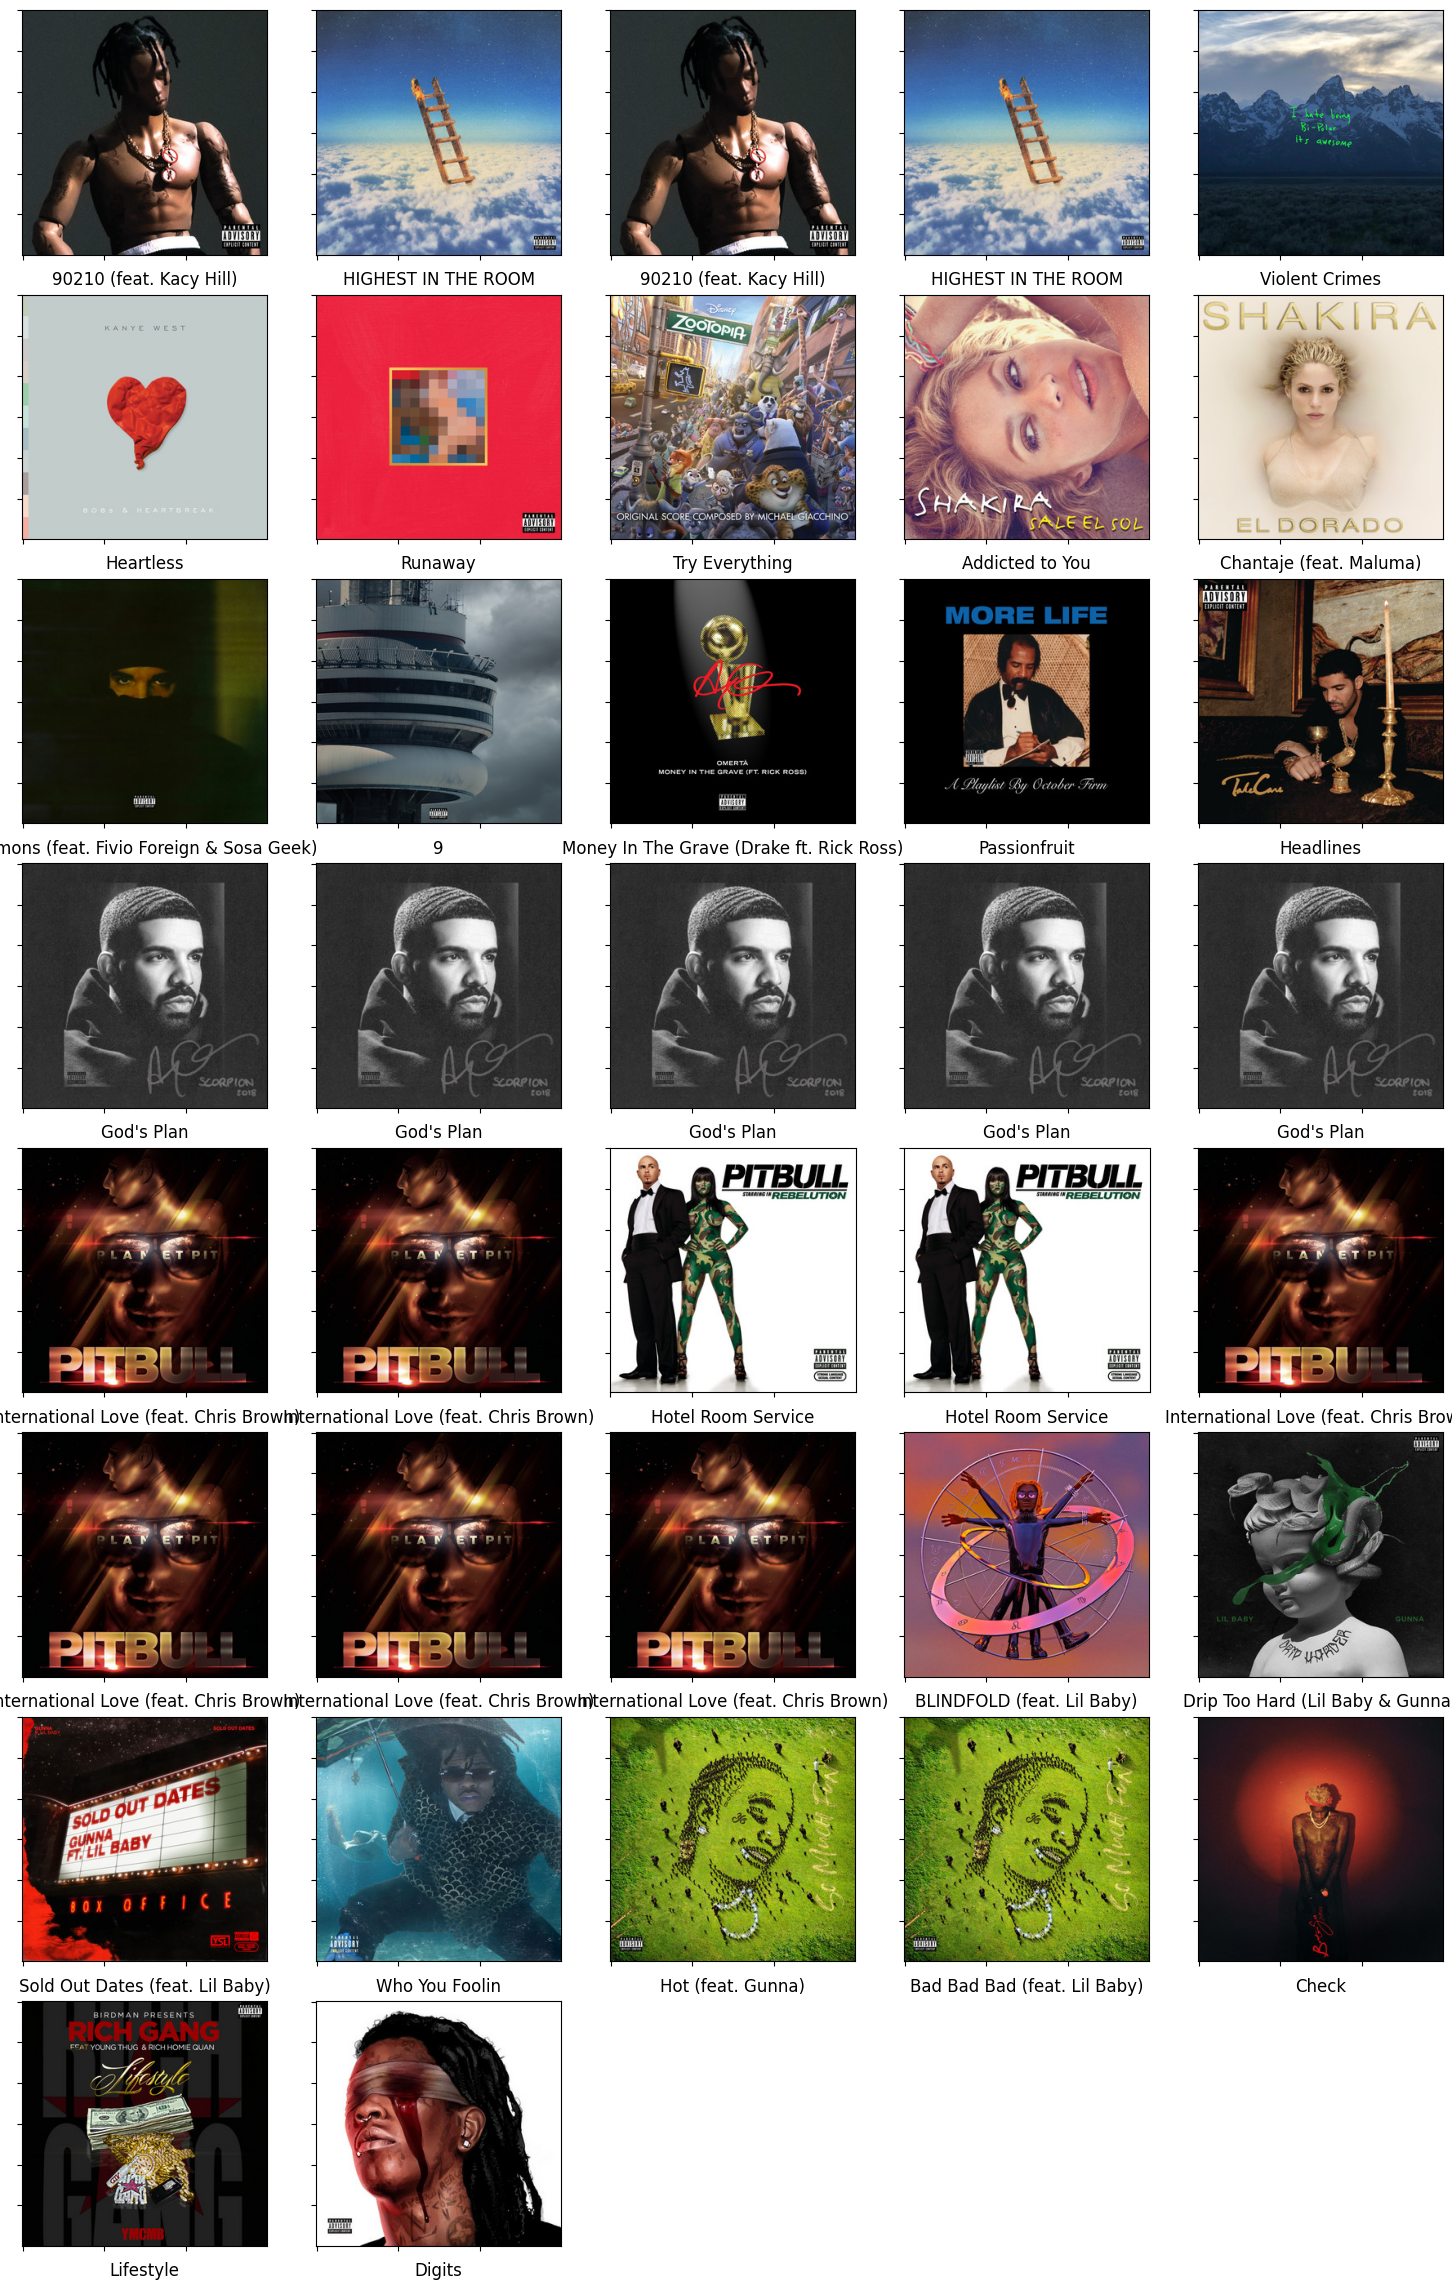

In [41]:
visualize_songs(playlist_1)

In [ ]:
def generate_playlist_feature(complete_feature_set, playlist_df, weight_factor):
    """ 
    Summarize a user's playlist into a single vector

    Parameters: 
        complete_feature_set (pandas dataframe): Dataframe which includes all of the features for the spotify songs
        playlist_df (pandas dataframe): playlist dataframe
        weight_factor (float): float value that represents the recency bias. The larger the recency bias, the most priority recent songs get. Value should be close to 1. 
        
    Returns: 
        playlist_feature_set_weighted_final (pandas series): single feature that summarizes the playlist
        complete_feature_set_nonplaylist (pandas dataframe): 
    """
    
    complete_feature_set_playlist = complete_feature_set[complete_feature_set['id'].isin(playlist_df['id'].values)]  # Search in 160k songs for songs in the playlist
    complete_feature_set_playlist = complete_feature_set_playlist.merge(playlist_df[['id','date_added']], on = 'id', how = 'inner')  # Add the added date to the playlist
    complete_feature_set_nonplaylist = complete_feature_set[~complete_feature_set['id'].isin(playlist_df['id'].values)]  # What's not in my playlist
    
    playlist_feature_set = complete_feature_set_playlist.sort_values('date_added',ascending=False)  # Sort by descending added date

    most_recent_date = playlist_feature_set.iloc[0,-1]  # Most recent added date
    
    for ix, row in playlist_feature_set.iterrows():  # Look at each song in the playlist
        playlist_feature_set.loc[ix,'months_from_recent'] = int((most_recent_date.to_pydatetime() - row.iloc[-1].to_pydatetime()).days / 30)
        
    playlist_feature_set['weight'] = playlist_feature_set['months_from_recent'].apply(lambda x: weight_factor ** (-x))  # Calculate the gap in months between the most recent date and the added date of each song, then apply the weighting formula
    
    playlist_feature_set_weighted = playlist_feature_set.copy()
    # print(playlist_feature_set_weighted.iloc[:,:-4].columns)
    playlist_feature_set_weighted.update(playlist_feature_set_weighted.iloc[:,:-4].mul(playlist_feature_set_weighted.weight,0))  # Multiply all features (danceability, etc.) by the calculated weight. A song you love but that is old will count less in your "profile" than a new song.
    playlist_feature_set_weighted_final = playlist_feature_set_weighted.iloc[:, :-4]
    # playlist_feature_set_weighted_final['id'] = playlist_feature_set['id']
    
    return playlist_feature_set_weighted_final.sum(axis = 0), complete_feature_set_nonplaylist

In [43]:
complete_feature_set_playlist_vector_playlist_1, complete_feature_set_nonplaylist_playlist_1 = generate_playlist_feature(complete_feature_set, playlist_1, 1.09)

In [ ]:
def generate_playlist_recos(df, features, nonplaylist_features):
    """ 
    Pull songs from a specific playlist.

    Parameters: 
        df (pandas dataframe): spotify dataframe
        features (pandas series): summarized playlist feature
        nonplaylist_features (pandas dataframe): feature set of songs that are not in the selected playlist
        
    Returns: 
        non_playlist_df_top_40: Top 40 recommendations for that playlist
    """
    
    non_playlist_df = df[df['id'].isin(nonplaylist_features['id'].values)]
    non_playlist_df['sim'] = cosine_similarity(nonplaylist_features.drop('id', axis = 1).values, features.values.reshape(1, -1))[:,0]  # Cosine allows us to say: "No matter if this song is more or less intense than what I listen to, is its style (its direction) the same as mine?"
    non_playlist_df_top_40 = non_playlist_df.sort_values('sim',ascending = False).head(40)
    non_playlist_df_top_40['url'] = non_playlist_df_top_40['id'].apply(lambda x: sp.track(x)['album']['images'][1]['url'])
    
    return non_playlist_df_top_40

In [45]:
playlist_1_top40 = generate_playlist_recos(spotify_df, complete_feature_set_playlist_vector_playlist_1, complete_feature_set_nonplaylist_playlist_1)

In [46]:
playlist_1_top40

,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,artists_upd_v1,artists_upd_v2,artists_upd,artists_song,consolidates_genre_lists,popularity_red,sim,url
74526,0.8860,2018,0.06770,"['Lil Baby', 'Gunna', 'Drake']",0.753,194732,0.686,1,6wWaVoUOzLQJHd3bWAUpdZ,0.000000,1,0.1930,-5.415,0,"Never Recover (Lil Baby & Gunna, Drake)",70,2018-10-05,0.2840,132.055,"[Lil Baby, Gunna, Drake]",[],"[Lil Baby, Gunna, Drake]","Lil BabyNever Recover (Lil Baby & Gunna, Drake)","[toronto_rap, pop_rap, canadian_hip_hop, trap,...",14,0.750239,https://i.scdn.co/image/ab67616d00001e02ce159a...
47190,0.4960,2018,0.12900,"['Quavo', 'Drake']",0.853,156195,0.637,1,1rlIrbWboTRGeKfHhgbJRZ,0.000000,3,0.2670,-5.924,0,FLIP THE SWITCH (feat. Drake),68,2018-10-12,0.3310,86.048,"[Quavo, Drake]",[],"[Quavo, Drake]",QuavoFLIP THE SWITCH (feat. Drake),"[toronto_rap, canadian_hip_hop, trap, rap, mel...",13,0.710617,https://i.scdn.co/image/ab67616d00001e02a1fc73...
156271,0.2640,2018,0.24700,"['2 Chainz', 'Drake', 'Quavo']",0.888,225893,0.515,1,5S1IUPueD0xE0vj4zU3nSf,0.000000,1,0.4460,-6.246,1,Bigger Than You (feat. Drake & Quavo),64,2018-06-15,0.2710,141.009,"[2 Chainz, Drake, Quavo]",[],"[2 Chainz, Drake, Quavo]",2 ChainzBigger Than You (feat. Drake & Quavo),"[toronto_rap, canadian_hip_hop, trap, rap, mel...",12,0.709457,https://i.scdn.co/image/ab67616d00001e02c7a392...
62049,0.3950,2018,0.08760,"['Migos', 'Drake']",0.907,276147,0.633,1,6n4U3TlzUGhdSFbUUhTvLP,0.000003,2,0.1060,-5.145,1,Walk It Talk It,76,2018-01-26,0.1840,145.914,"[Migos, Drake]",[],"[Migos, Drake]",MigosWalk It Talk It,"[toronto_rap, canadian_hip_hop, trap, rap, hip...",15,0.708833,https://i.scdn.co/image/ab67616d00001e029c188c...
74512,0.5620,2018,0.03550,"['Lil Baby', 'Drake']",0.963,142273,0.346,1,6vN77lE9LK6HP2DewaN6HZ,0.000000,5,0.1080,-9.309,0,Yes Indeed,79,2018-05-18,0.5300,119.957,"[Lil Baby, Drake]",[],"[Lil Baby, Drake]",Lil BabyYes Indeed,"[toronto_rap, pop_rap, canadian_hip_hop, rap, ...",15,0.698458,https://i.scdn.co/image/ab67616d00001e026cab41...
29329,0.3290,2019,0.08240,"['Swae Lee', 'Drake']",0.915,218710,0.588,0,2sqsNXfN0HtgDEgaHXiUTa,0.000169,7,0.1040,-6.302,0,Won't Be Late (feat. Drake),72,2019-08-16,0.0677,123.936,"[Swae Lee, Drake]",[],"[Swae Lee, Drake]",Swae LeeWon't Be Late (feat. Drake),"[toronto_rap, canadian_hip_hop, trap, rap, mel...",14,0.694383,https://i.scdn.co/image/ab67616d00001e0216755a...
121870,0.5980,2017,0.08000,"['Drake', 'Young Thug']",0.813,250770,0.551,1,7bJ4mu7MHa3rHiNyKjOoSl,0.000000,6,0.3860,-7.605,0,Ice Melts,60,2017-03-18,0.3530,124.957,"[Drake, Young Thug]",[],"[Drake, Young Thug]",DrakeIce Melts,"[toronto_rap, canadian_hip_hop, trap, rap, atl...",12,0.687710,https://i.scdn.co/image/ab67616d00001e024f0fd9...
100459,0.4050,2018,0.09890,"['Gunna', 'NAV', 'Metro Boomin']",0.859,219817,0.574,1,4xisLMFhYADhKnkOCCV4Am,0.000000,7,0.0918,-6.160,1,Car Sick (feat. NAV & Metro Boomin),59,2018-02-02,0.3990,149.995,"[Gunna, NAV, Metro Boomin]",[],"[Gunna, NAV, Metro Boomin]",GunnaCar Sick (feat. NAV & Metro Boomin),"[toronto_rap, canadian_hip_hop, trap, rap, mel...",11,0.685415,https://i.scdn.co/image/ab67616d00001e022126ce...
62811,0.2030,2018,0.07090,"['Metro Boomin', 'Offset', 'Drake']",0.914,265480,0.572,1,156LzfvMNKuXuiot4uzhGD,0.002370,2,0.0599,-8.820,1,No Complaints (feat. Offset & Drake) (Bonus),67,2018-11-06,0.1660,123.963,"[Metro Boomin, Offset, Drake]",[],"[Metro Boomin, Offset, Drake]",Metro BoominNo Complaints (feat. Offset & Drak...,"[toronto_rap, canadian_hip_hop, trap, rap, hip...",13,0.685192,https://i.scdn.co/image/ab67616d00001e022887f8...
107836,0.8150,2020,0.01280,"['Future', 'Drake', 'Young Thug']",0.718,189176,0.706,1,5fHrHoJKfCgBd35zwIBmUK,0.000000,1,0.3520,-5.709,1,D4L,68,2020-05-01,0.0600,170.004,"[Future, Drake, Young Thug]",[],"[Future, Drake, Young Thug]",FutureD4L,"[toronto_rap, canadian_hip_hop, trap, rap, atl...",